# Expanded Multi-Regime PPO and DQN Training

This notebook runs the 30-stock plus four defensive-asset experiment. It uses causal regime features, sector and position caps, weekly allocation decisions, regime-balanced training episodes, strong rolling baselines, and a shared per-asset encoder for PPO and DQN. The 2022-2025 test is locked unless `RUN_FINAL_TEST` is changed explicitly.

> The Yahoo Finance stock universe is exploratory because it is not delisting-complete or point-in-time. Replace it with point-in-time constituent data before making a survivorship-free stock-selection claim.

In [1]:
from pathlib import Path
import os
import sys
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import matplotlib.pyplot as plt
import pandas as pd
from src.agents.train_agents import train_dqn, train_ppo
from src.data.regimes import HISTORICAL_REGIMES
from src.data.splits import chronological_split
from src.data.universe import EXPANDED_SECTORS, EXPANDED_TICKERS
from src.evaluation.expanded import baseline_walk_forward_report
from src.expanded_experiment import (
    _scale_features, load_expanded_data, prepare_expanded_data,
    run_expanded_experiment, smoke_config,
)
from src.utils.config import EXPANDED_CONFIG

PREPARE_DATA = False       # True downloads and rebuilds expanded data.
TRAIN_AGENTS = True        # True trains both PPO and DQN.
USE_SMOKE_PROFILE = False   # One seed/50k steps; False uses five seeds.
RUN_FINAL_TEST = True    
CONFIG = smoke_config() if USE_SMOKE_PROFILE else EXPANDED_CONFIG
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
print({'profile': 'smoke' if USE_SMOKE_PROFILE else 'full',
       'assets': len(EXPANDED_TICKERS), 'seeds': CONFIG.training_seeds,
       'ppo_steps': CONFIG.ppo_timesteps,
       'dqn_steps': CONFIG.dqn_timesteps,
       'rebalance_days': CONFIG.rebalance_frequency,
       'action_smoothing': CONFIG.action_smoothing,
       'no_trade_turnover': CONFIG.minimum_rebalance_turnover,
       'max_rebalance_turnover': CONFIG.maximum_rebalance_turnover,
       'ppo_device': CONFIG.ppo_device or CONFIG.device,
       'dqn_device': CONFIG.dqn_device or CONFIG.device,
       'dqn_buffer': CONFIG.dqn_buffer_size,
       'model_directory': str(CONFIG.model_directory)})

{'profile': 'full', 'assets': 34, 'seeds': (42, 73, 101, 131, 173), 'ppo_steps': 750000, 'dqn_steps': 750000, 'rebalance_days': 21, 'action_smoothing': 0.25, 'no_trade_turnover': 0.05, 'max_rebalance_turnover': 0.25, 'ppo_device': 'cpu', 'dqn_device': 'cuda', 'dqn_buffer': 50000, 'model_directory': 'results\\models\\expanded_v2'}


## 1. Prepare data

The first run requires internet access. Regime thresholds and mixture components are fitted only through 2018.

In [2]:
if PREPARE_DATA:
    prepare_expanded_data()
elif not EXPANDED_CONFIG.returns_path.exists():
    raise FileNotFoundError('Set PREPARE_DATA = True and rerun this cell.')
else:
    print(f'Using existing {EXPANDED_CONFIG.returns_path}')

Using existing data\processed\expanded_returns.csv


## 2. Frozen split and train-only scaling

In [3]:
returns, features, regimes = load_expanded_data()
train_returns, validation_returns, test_returns = chronological_split(
    returns, CONFIG.train_end, CONFIG.validation_end
)
train_features, validation_features, test_features = _scale_features(
    features.loc[train_returns.index],
    features.loc[validation_returns.index],
    features.loc[test_returns.index],
    config=CONFIG,
)
pd.DataFrame({
    'observations': [len(train_returns), len(validation_returns), len(test_returns)],
    'start': [train_returns.index.min(), validation_returns.index.min(), test_returns.index.min()],
    'end': [train_returns.index.max(), validation_returns.index.max(), test_returns.index.max()],
}, index=['train', 'validation', 'locked test'])

,observations,start,end
train,2667,2008-05-29,2018-12-31
validation,757,2019-01-02,2021-12-31
locked test,1003,2022-01-03,2025-12-31


## 3. Audit the universe and causal regime coverage

,label,start,end,description
key,,,,
regime_1,Regime 1 — GFC Aftermath and Euro-Area Stress,2008-01-01,2013-12-31,Elevated volatility and the sovereign-debt cri...
regime_2,Regime 2 — Post-Crisis Expansion,2014-01-01,2019-12-31,Low rates and comparatively steady growth.
regime_3,Regime 3 — COVID Crash and Recovery,2020-01-01,2021-12-31,Extreme drawdown followed by a rapid rebound.
regime_4,Regime 4 — Inflation Shock and Rate Hikes,2022-01-01,2025-12-31,Aggressive Fed tightening and a bond sell-off.


,assets
sector,
Broad Equity,1
Cash Equivalent,1
Communication Services,3
Consumer Discretionary,3
Consumer Staples,3
Energy,3
Financials,3
Gold,1
Health Care,3


col_0,locked test,train,validation
regime,,,
Regime 1 — GFC Aftermath and Euro-Area Stress,0,1409,0
Regime 2 — Post-Crisis Expansion,0,1258,252
Regime 3 — COVID Crash and Recovery,0,0,505
Regime 4 — Inflation Shock and Rate Hikes,1003,0,0


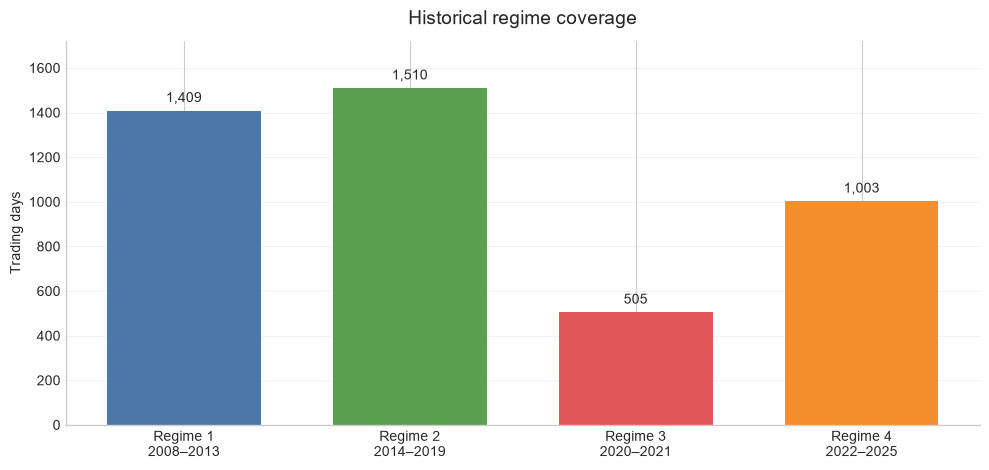

In [4]:
regime_definition = pd.DataFrame(HISTORICAL_REGIMES).set_index('key')
display(regime_definition[['label', 'start', 'end', 'description']])
universe = pd.DataFrame({'ticker': EXPANDED_TICKERS,
    'sector': [EXPANDED_SECTORS[t] for t in EXPANDED_TICKERS]})
display(universe.groupby('sector').size().rename('assets').to_frame())
period = pd.Series('train', index=regimes.index)
period.loc[period.index > pd.Timestamp(CONFIG.train_end)] = 'validation'
period.loc[period.index > pd.Timestamp(CONFIG.validation_end)] = 'locked test'
regime_order = [item['label'] for item in HISTORICAL_REGIMES]
regime_ticks = [
    f"Regime {index}\n{item['start'][:4]}–{item['end'][:4]}"
    for index, item in enumerate(HISTORICAL_REGIMES, start=1)
]
regime_table = pd.crosstab(regimes, period).reindex(regime_order, fill_value=0)
display(regime_table)
regime_counts = regimes.value_counts().reindex(regime_order, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.bar(regime_ticks, regime_counts.values,
              color=['#4C78A8', '#59A14F', '#E15759', '#F28E2B'],
              width=0.68)
ax.bar_label(bars, labels=[f'{value:,}' for value in regime_counts.values],
             padding=4, fontsize=10)
ax.set_title('Historical regime coverage', fontsize=14, pad=12)
ax.set_ylabel('Trading days')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=0)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.25)
ax.margins(y=0.14)
plt.tight_layout()

## 4. Strong baseline walk-forward tests


annualised_return  sharpe_ratio  maximum_drawdown  \
fold strategy                                                          
1    Equal Weight             0.0469        0.4380            0.1359   
     Markowitz                0.0868        0.7485            0.1057   
2    Equal Weight             0.2370        2.3440            0.0755   
     Markowitz                0.1532        1.6482            0.0664   
3    Equal Weight             0.1336        1.1027            0.1273   
     Markowitz                0.0947        0.8130            0.1542   
4    Equal Weight             0.2075        0.9305            0.2985   
     Markowitz                0.2318        1.0564            0.2641   

                   calmar_ratio  
fold strategy                    
1    Equal Weight        0.3447  
     Markowitz           0.8208  
2    Equal Weight        3.1404  
     Markowitz           2.3062  
3    Equal Weight        1.0495  
     Markowitz           0.6138  
4    Equal Weight        0.6951  
     Markowitz           0.8777

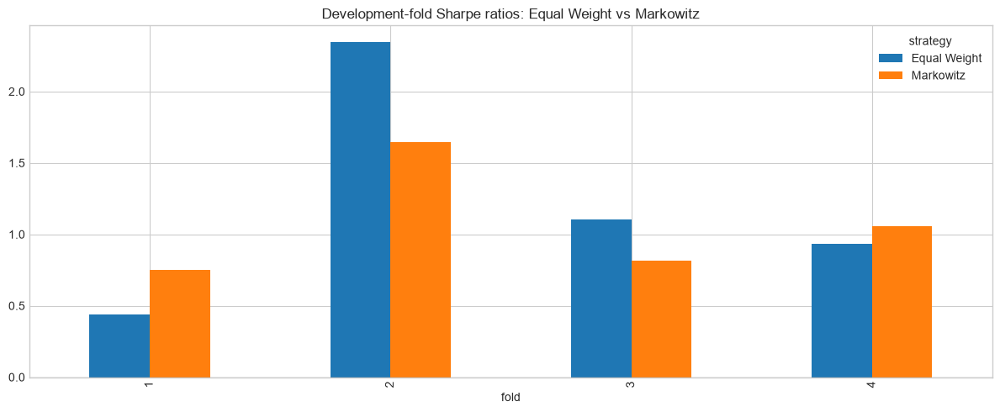

In [5]:
walk_forward = baseline_walk_forward_report(returns.loc[:CONFIG.validation_end], CONFIG)
strategy_map = {'Equal Weight': 'Equal Weight', 'Shrinkage Markowitz': 'Markowitz'}
comparison = (walk_forward.reset_index()
    .loc[lambda frame: frame['strategy'].isin(strategy_map)]
    .assign(strategy=lambda frame: frame['strategy'].map(strategy_map)))
display(comparison.set_index(['fold', 'strategy'])[[
    'annualised_return', 'sharpe_ratio', 'maximum_drawdown', 'calmar_ratio'
]])
comparison.pivot(index='fold', columns='strategy', values='sharpe_ratio').reindex(
    columns=['Equal Weight', 'Markowitz']
).plot(kind='bar', figsize=(12, 5),
       title='Development-fold Sharpe ratios: Equal Weight vs Markowitz')
plt.axhline(0, color='black', linewidth=0.8); plt.tight_layout()

## 5. Train PPO and DQN

Start with the smoke profile. The full profile uses five seeds per agent and can take a long time. approximately 2:30 with RTX 5070 and Intel Core Ultra 7 with RAM 32 GB

In [7]:
if TRAIN_AGENTS:
    ppo_path = train_ppo(
        train_returns, validation_returns, CONFIG,
        train_features=train_features,
        validation_features=validation_features,
        train_regimes=regimes.loc[train_returns.index],
        validation_regimes=regimes.loc[validation_returns.index],
    )
    dqn_path = train_dqn(
        train_returns, validation_returns, CONFIG,
        train_features=train_features,
        validation_features=validation_features,
        train_regimes=regimes.loc[train_returns.index],
        validation_regimes=regimes.loc[validation_returns.index],
    )
    print(f'Saved PPO candidate: {ppo_path}')
    print(f'Saved DQN candidate: {dqn_path}')
else:
    print('Training skipped. Set TRAIN_AGENTS = True when ready.')

Using cpu device
Logging to results\reports\expanded_v2\tensorboard\ppo_seed_42_1
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 12       |
|    ep_rew_mean     | 11.3     |
| time/              |          |
|    fps             | 638      |
|    iterations      | 1        |
|    time_elapsed    | 3        |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 12          |
|    ep_rew_mean          | 14          |
| time/                   |             |
|    fps                  | 592         |
|    iterations           | 2           |
|    time_elapsed         | 6           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.004864876 |
|    clip_fraction        | 0.0892      |
|    clip_range           | 0.15        |
|    entropy_loss         | -48.

## 6. Inspect validation histories without touching the test

,algorithm,seed,timesteps,robust_score,worst_period_sharpe,mean_turnover,maximum_drawdown
2,DQN,101,45000,1.1147,0.9683,0.0077,0.3195
2,DQN,131,45000,1.0411,0.8915,0.0082,0.3089
2,DQN,173,45000,0.9948,0.8352,0.0072,0.2926
2,DQN,42,45000,1.0535,0.9192,0.0079,0.3156
2,DQN,73,45000,1.1081,0.9420,0.0073,0.3199
...,...,...,...,...,...,...,...
25,PPO,101,390000,1.1305,1.0033,0.0012,0.2972
25,PPO,131,390000,1.1362,0.9791,0.0013,0.2931
25,PPO,173,390000,1.1442,1.0033,0.0012,0.3001
25,PPO,42,390000,1.1498,1.0044,0.0008,0.2903


Validation gate passed: False


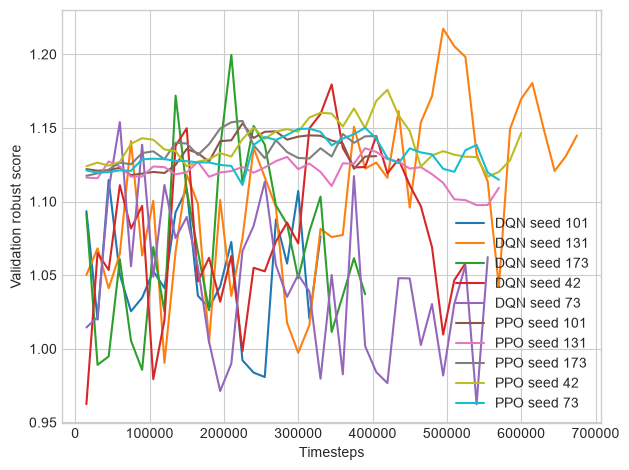

In [18]:
validation_gate_passed = True
history_files = sorted((CONFIG.report_directory / 'training').glob(
    '*_seed_*_validation.csv'))
if history_files:
    histories = pd.concat([pd.read_csv(path).assign(
        algorithm=path.stem.split('_')[0].upper(),
        seed=path.stem.split('_')[2]) for path in history_files])
    best_rows = histories.loc[histories.groupby(
        ['algorithm', 'seed'])['robust_score'].idxmax()].copy()
    display(best_rows[['algorithm', 'seed', 'timesteps', 'robust_score',
                       'worst_period_sharpe', 'mean_turnover',
                       'maximum_drawdown']])
    validation_gate_passed = bool(
        (best_rows['mean_turnover'] <= 0.03).all()
        and (best_rows['worst_period_sharpe'] > 0).all()
        and (best_rows['maximum_drawdown'] <= 0.30).all()
    )
    print(f'Validation gate passed: {validation_gate_passed}')
    for (algorithm, seed), history in histories.groupby(['algorithm', 'seed']):
        plt.plot(history.timesteps, history.robust_score,
                 label=f'{algorithm} seed {seed}')
    plt.xlabel('Timesteps'); plt.ylabel('Validation robust score')
    plt.legend(); plt.tight_layout()
else:
    print('No validation histories exist yet.')

## 7. Explicitly unlock the final test


In [19]:
gate_history_files = sorted((CONFIG.report_directory / 'training').glob(
    '*_seed_*_validation.csv'))
required_algorithms = {'PPO', 'DQN'}
gate_passed = False
gate_reason = 'No validation histories were found.'

if gate_history_files:
    gate_histories = pd.concat([
        pd.read_csv(path).assign(
            algorithm=path.stem.split('_')[0].upper(),
            seed=int(path.stem.split('_')[2]),
        )
        for path in gate_history_files
    ], ignore_index=True)
    gate_best_rows = gate_histories.loc[gate_histories.groupby(
        ['algorithm', 'seed'])['robust_score'].idxmax()].copy()
    available_algorithms = set(gate_best_rows['algorithm'])
    histories_complete = required_algorithms.issubset(available_algorithms)
    turnover_ok = bool((gate_best_rows['mean_turnover'] <= 0.03).all())
    worst_regime_ok = bool((gate_best_rows['worst_period_sharpe'] > 0).all())
    drawdown_ok = bool((gate_best_rows['maximum_drawdown'] <= 0.30).all())
    required_models = [
        CONFIG.model_directory / 'ppo_portfolio.zip',
        CONFIG.model_directory / 'dqn_portfolio.zip',
    ]
    models_exist = all(path.exists() for path in required_models)
    gate_passed = bool(histories_complete and turnover_ok
                       and worst_regime_ok and drawdown_ok and models_exist)
    gate_reason = {
        'both_histories': histories_complete,
        'turnover_at_most_3pct': turnover_ok,
        'positive_worst_regime_sharpe': worst_regime_ok,
        'drawdown_at_most_30pct': drawdown_ok,
        'both_models_exist': models_exist,
    }
    display(gate_best_rows[['algorithm', 'seed', 'timesteps',
                            'robust_score', 'worst_period_sharpe',
                            'mean_turnover', 'maximum_drawdown']])

print(f'Post-hoc evaluation gate: {gate_reason}')
if RUN_FINAL_TEST and gate_passed:
    run_expanded_experiment(
        skip_training=True,
        smoke=USE_SMOKE_PROFILE,
        evaluate_final=True,
    )
elif RUN_FINAL_TEST:
    print('Post-hoc evaluation blocked until every gate passes.')
else:
    print('Post-hoc evaluation remains disabled.')

,algorithm,seed,timesteps,robust_score,worst_period_sharpe,mean_turnover,maximum_drawdown
115,DQN,42,345000,1.1795,0.9926,0.0080,0.2936
131,DQN,73,60000,1.1540,1.0270,0.0076,0.2889
2,DQN,101,45000,1.1147,0.9683,0.0077,0.3195
54,DQN,131,495000,1.2173,0.9834,0.0074,0.3117
80,DQN,173,210000,1.1996,0.9935,0.0084,0.2978
284,PPO,42,420000,1.1759,1.0287,0.0011,0.2839
322,PPO,73,390000,1.1501,1.0123,0.0012,0.2912
179,PPO,101,225000,1.1531,1.0030,0.0005,0.2933
217,PPO,131,390000,1.1362,0.9791,0.0013,0.2931
244,PPO,173,225000,1.1547,1.0098,0.0006,0.2931


Post-hoc evaluation gate: {'both_histories': True, 'turnover_at_most_3pct': True, 'positive_worst_regime_sharpe': True, 'drawdown_at_most_30pct': False, 'both_models_exist': True}
Post-hoc evaluation blocked until every gate passes.


## 8. Review final evidence, if unlocked

,total_return,annualised_return,annualised_volatility,sharpe_ratio,sortino_ratio,maximum_drawdown,calmar_ratio,mean_daily_turnover,total_trading_cost,mean_concentration
Markowitz,0.3502,0.0800,0.1221,0.6915,0.6640,0.1662,0.4814,0.0197,0.0296,0.0702
Equal Weight,0.4844,0.1066,0.1336,0.8247,0.8047,0.1639,0.6501,0.0023,0.0034,0.0295
DQN,0.4822,0.1061,0.1358,0.8106,0.7871,0.1554,0.6829,0.0062,0.0092,0.0347
PPO,0.4520,0.1003,0.1335,0.7830,0.7591,0.1663,0.6034,0.0010,0.0014,0.0321


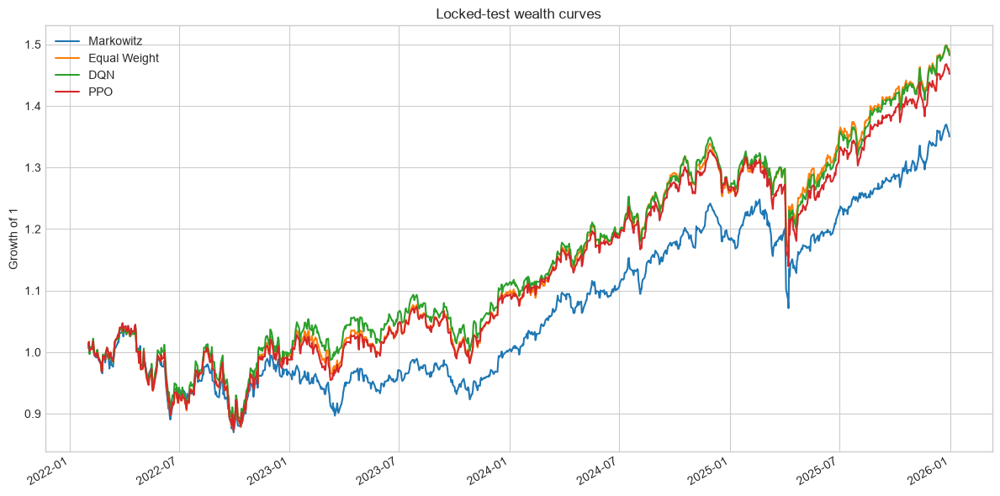

In [6]:
metrics_path = CONFIG.report_directory / 'performance_metrics.csv'
returns_path = CONFIG.report_directory / 'out_of_sample_returns.csv'

if metrics_path.exists() and returns_path.exists():
    final_metrics = pd.read_csv(metrics_path, index_col=0)
    final_returns = pd.read_csv(
        returns_path, index_col=0, parse_dates=True
    )

    # Expanded evaluation saves Markowitz as “Shrinkage Markowitz”.
    strategy_map = {
        'Shrinkage Markowitz': 'Markowitz',
        'Equal Weight': 'Equal Weight',
        'DQN': 'DQN',
        'PPO': 'PPO',
    }

    available_strategies = [
        source for source in strategy_map
        if source in final_metrics.index and source in final_returns.columns
    ]
    missing_strategies = [
        label for source, label in strategy_map.items()
        if source not in available_strategies
    ]

    if missing_strategies:
        print(f'Not present in the saved reports: {missing_strategies}')

    comparison_metrics = final_metrics.loc[available_strategies].rename(
        index=strategy_map
    )
    comparison_returns = final_returns.loc[:, available_strategies].rename(
        columns=strategy_map
    )

    display(comparison_metrics)

    (1 + comparison_returns).cumprod().plot(
        figsize=(12, 6),
        title='Locked-test wealth curves',
    )
    plt.ylabel('Growth of 1')
    plt.tight_layout()
else:
    print('No final-test reports exist yet.')

## 9. Direct PPO versus DQN comparison



Found 10 validation histories for comparison.
Best validation robust score by agent


algorithm,DQN,PPO
seed,,
42,1.1795,1.1759
73,1.1540,1.1501
101,1.1147,1.1531
131,1.2173,1.1362
173,1.1996,1.1547


Final PPO/DQN comparison


,annualised_return,sharpe_ratio,sortino_ratio,maximum_drawdown,mean_daily_turnover,total_trading_cost
PPO,0.1003,0.7830,0.7591,0.1663,0.0010,0.0014
DQN,0.1061,0.8106,0.7871,0.1554,0.0062,0.0092


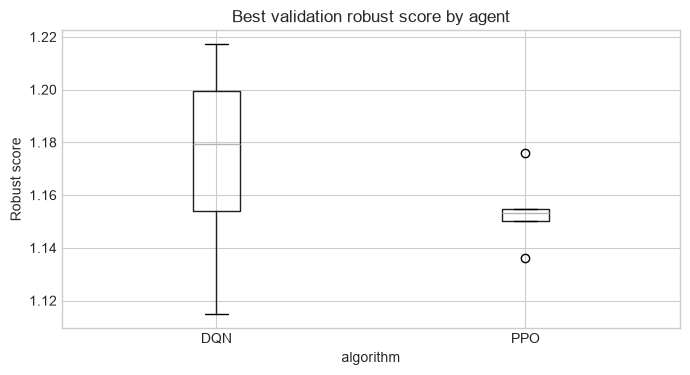

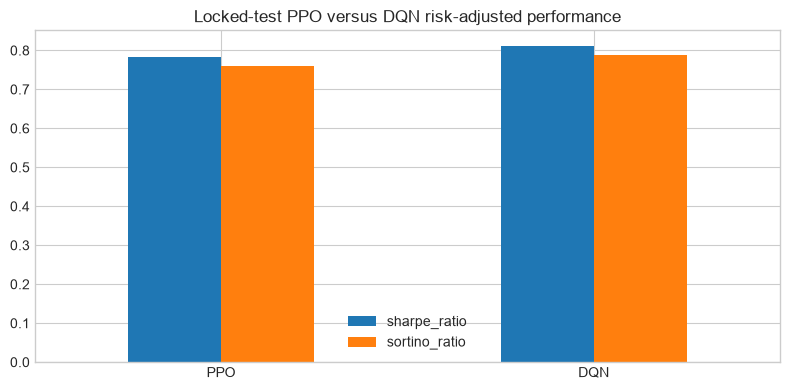

In [28]:
comparison_history_files = sorted((CONFIG.report_directory / 'training').glob(
    '*_seed_*_validation.csv'))
if comparison_history_files:
    print(f'Found {len(comparison_history_files)} validation histories for comparison.')
    comparison_histories = pd.concat([
        pd.read_csv(path).assign(
            algorithm=path.stem.split('_')[0].upper(),
            seed=int(path.stem.split('_')[2]),
        )
        for path in comparison_history_files
    ], ignore_index=True)
    print('Best validation robust score by agent')
    best_validation = (comparison_histories
        .groupby(['algorithm', 'seed'], as_index=False)['robust_score'].max())
    display(best_validation.pivot(index='seed', columns='algorithm',
                                  values='robust_score'))
    best_validation.boxplot(column='robust_score', by='algorithm', figsize=(7, 4))
    plt.suptitle(''); plt.title('Best validation robust score by agent')
    plt.ylabel('Robust score'); plt.tight_layout()
else:
    print('Train PPO and DQN to generate validation comparisons.')

if metrics_path.exists() and returns_path.exists():
    print('Final PPO/DQN comparison')
    agent_order = [name for name in ['PPO', 'DQN'] if name in final_metrics.index]
    comparison_columns = [column for column in [
        'annualised_return', 'sharpe_ratio', 'sortino_ratio',
        'maximum_drawdown', 'mean_daily_turnover', 'total_trading_cost'
    ] if column in final_metrics.columns]
    agent_comparison = final_metrics.loc[agent_order, comparison_columns]
    display(agent_comparison)
    agent_comparison[['sharpe_ratio', 'sortino_ratio']].plot.bar(
        figsize=(8, 4), title='Locked-test PPO versus DQN risk-adjusted performance')
    plt.xticks(rotation=0); plt.tight_layout()
else:
    print('Final PPO/DQN comparison remains locked.')